# WildGuard YOLO26 model comparison

This notebook compares the three one-class driver-animal checkpoints developed for WildGuard:

- **YOLO26s v2:** conservative baseline trained with reviewed road positives.
- **YOLO26s v3:** targeted hard-negative transfer experiment.
- **YOLO26n:** compact deployment candidate trained from COCO initialization on the same frozen benchmark.

The goal is to distinguish the best **hackathon deployment candidate** from a production-proven safety model. All models use the shared `animal` detection label, but the current positive training coverage is primarily deer.

## Evaluation boundaries

- Still-image metrics use the same frozen validation and test splits.
- Tesla is useful for visual behavior, but it contributed training examples and is not an independent generalization test.
- The two unseen videos do not have complete frame-level ground truth. Detection volume therefore measures alert activity, not accuracy.
- The 12-image gallery is deterministic and illustrative; the full frozen test metrics remain the stronger quantitative evidence.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'README.md').is_file():
    ROOT = next(parent for parent in Path.cwd().parents if (parent / 'README.md').is_file())

def load_json(relative_path):
    with (ROOT / relative_path).open(encoding='utf-8') as handle:
        return json.load(handle)

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'YOLO26s v2': '#2563eb', 'YOLO26s v3': '#f59e0b', 'YOLO26n': '#16a34a'}

nano_summary = load_json('storage/models/driver_animal_nano/training_summary.json')
v3_summary = load_json('storage/models/driver_animal_v3/training_summary.json')
print(f'Repository: {ROOT}')

Repository: /home/vivek/Documents/Vivek-projects/WildGuard


## 1. Frozen still-image benchmark

mAP50–95 is the primary localization metric. Precision indicates resistance to false boxes, while recall measures how many labeled animals are recovered.

In [2]:
nano_comparison = nano_summary['validation_and_test_comparison']
metrics_by_model = {
    'YOLO26s v2': nano_comparison['yolo26s_v2'],
    'YOLO26s v3': v3_summary['validation_and_test_comparison']['new'],
    'YOLO26n': nano_comparison['yolo26n'],
}

rows = []
for model, splits in metrics_by_model.items():
    for split in ('val', 'test'):
        rows.append({'model': model, 'split': split, **{
            key: splits[split][key]
            for key in ('precision', 'recall', 'map50', 'map50_95')
        }})
metrics_df = pd.DataFrame(rows)
display(metrics_df.round(3))

,model,split,precision,recall,map50,map50_95
0,YOLO26s v2,val,0.934,0.886,0.933,0.698
1,YOLO26s v2,test,0.901,0.847,0.874,0.651
2,YOLO26s v3,val,0.937,0.894,0.932,0.699
3,YOLO26s v3,test,0.926,0.829,0.877,0.647
4,YOLO26n,val,0.955,0.869,0.911,0.679
5,YOLO26n,test,0.873,0.838,0.865,0.660


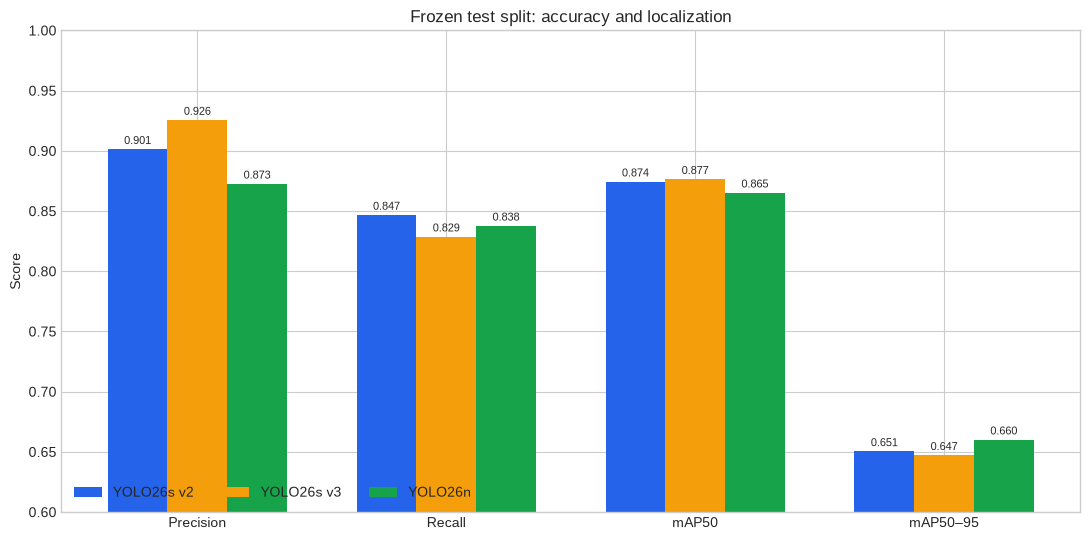

In [3]:
test_df = metrics_df.query("split == 'test'").set_index('model')
plot_metrics = ['precision', 'recall', 'map50', 'map50_95']
labels = ['Precision', 'Recall', 'mAP50', 'mAP50–95']
x = np.arange(len(plot_metrics))
width = 0.24
fig, ax = plt.subplots(figsize=(11, 5.5))
for index, model in enumerate(test_df.index):
    values = test_df.loc[model, plot_metrics].to_numpy(dtype=float)
    bars = ax.bar(x + (index - 1) * width, values, width, label=model, color=COLORS[model])
    ax.bar_label(bars, fmt='%.3f', fontsize=8, padding=2)
ax.set_xticks(x, labels)
ax.set_ylim(0.60, 1.0)
ax.set_ylabel('Score')
ax.set_title('Frozen test split: accuracy and localization')
ax.legend(ncols=3, loc='lower left')
plt.tight_layout()
plt.show()

**Interpretation:** YOLO26n has the highest test mAP50–95 (0.660), while v2 retains slightly stronger precision and recall. V3 has the highest precision but the lowest recall and mAP50–95 of the three. The differences are small enough that deployment behavior matters.

## 2. Accuracy versus deployment cost

In [4]:
checkpoint_paths = {
    'YOLO26s v2': ROOT / 'storage/models/driver_animal_v2/best.pt',
    'YOLO26s v3': ROOT / 'storage/models/driver_animal_v3/best.pt',
    'YOLO26n': ROOT / 'storage/models/driver_animal_nano/best.pt',
}
parameter_counts = {
    'YOLO26s v2': 9_465_567,
    'YOLO26s v3': 9_465_567,
    'YOLO26n': nano_summary['parameters'],
}
deployment_df = pd.DataFrame([
    {
        'model': model,
        'parameters_m': parameter_counts[model] / 1e6,
        'checkpoint_mb': path.stat().st_size / 1e6,
        'test_map50_95': test_df.loc[model, 'map50_95'],
        'test_inference_ms': (
            nano_comparison['yolo26n' if model == 'YOLO26n' else 'yolo26s_v2']['test']['inference_ms_per_image']
            if model != 'YOLO26s v3' else np.nan
        ),
    }
    for model, path in checkpoint_paths.items()
])
display(deployment_df.round(3))

,model,parameters_m,checkpoint_mb,test_map50_95,test_inference_ms
0,YOLO26s v2,9.466,20.343,0.651,4.502
1,YOLO26s v3,9.466,20.341,0.647,NaN
2,YOLO26n,2.534,5.491,0.660,3.335


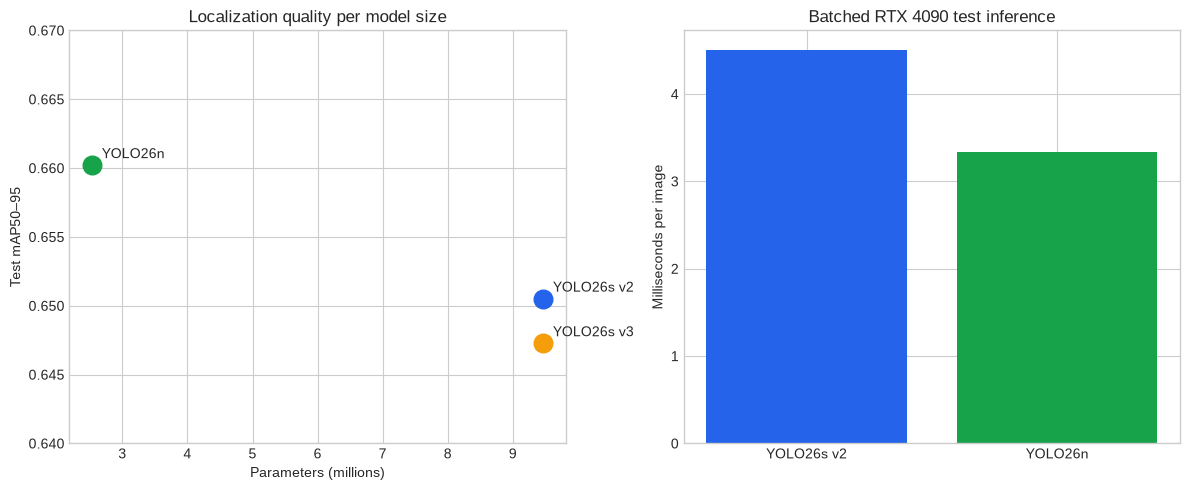

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for _, row in deployment_df.iterrows():
    axes[0].scatter(row['parameters_m'], row['test_map50_95'], s=180, color=COLORS[row['model']], label=row['model'])
    axes[0].annotate(row['model'], (row['parameters_m'], row['test_map50_95']), xytext=(7, 5), textcoords='offset points')
speed_df = deployment_df.dropna(subset=['test_inference_ms'])
axes[1].bar(speed_df['model'], speed_df['test_inference_ms'], color=[COLORS[name] for name in speed_df['model']])
axes[1].set_ylabel('Milliseconds per image')
axes[1].set_title('Batched RTX 4090 test inference')
axes[0].set_xlabel('Parameters (millions)')
axes[0].set_ylabel('Test mAP50–95')
axes[0].set_title('Localization quality per model size')
axes[0].set_ylim(0.64, 0.67)
plt.tight_layout()
plt.show()

YOLO26n uses roughly one quarter of the parameters and a 5.5 MB checkpoint. In the comparable batched benchmark it was about 26% faster than v2 while slightly improving test mAP50–95.

## 3. Tesla event timeline at confidence 0.10

The green segment marks the primary deer encounter. Orange segments are other model events. Tesla supplied training examples, so this is a behavior visualization rather than independent test evidence.

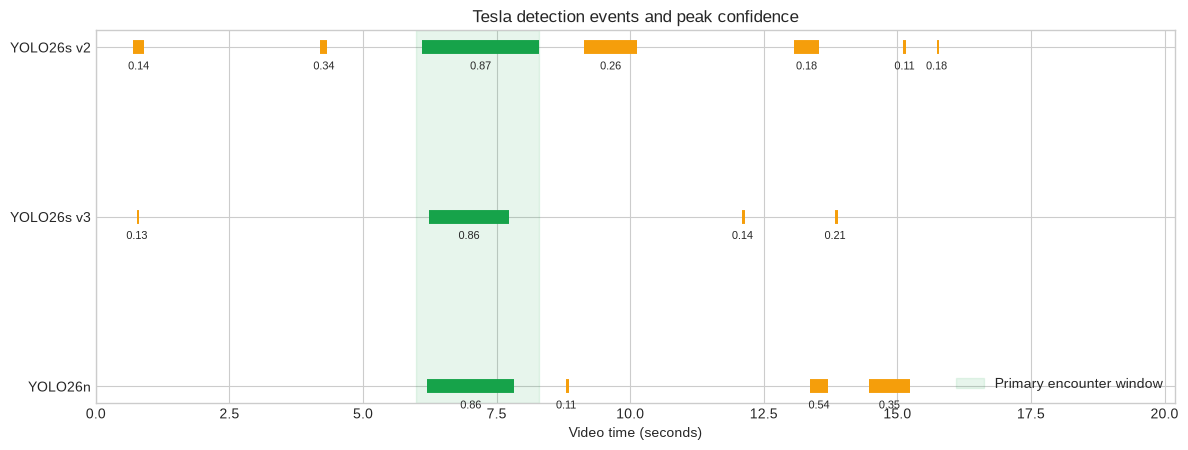

In [6]:
tesla_reports = {
    'YOLO26s v2': load_json('storage/evidence/tesla_model_comparison/driver_animal_v2/report.json'),
    'YOLO26s v3': load_json('storage/evidence/tesla_model_comparison/driver_animal_v3/report.json'),
    'YOLO26n': load_json('storage/evidence/tesla_model_comparison/driver_animal_nano/report.json'),
}
fig, ax = plt.subplots(figsize=(12, 4.6))
model_order = list(tesla_reports)
for y, model in enumerate(model_order):
    for event in tesla_reports[model]['videos'][0]['events']:
        start, end = event['start_seconds'], event['end_seconds']
        primary = start <= 8.3 and end >= 6.0
        color = '#16a34a' if primary else '#f59e0b'
        ax.plot([start, max(end, start + 0.05)], [y, y], linewidth=10, solid_capstyle='butt', color=color)
        ax.text((start + end) / 2, y + 0.13, f"{event['max_confidence']:.2f}", ha='center', fontsize=8)
ax.axvspan(6.0, 8.3, color='#16a34a', alpha=0.10, label='Primary encounter window')
ax.set_yticks(range(len(model_order)), model_order)
ax.set_xlim(0, 20.2)
ax.set_xlabel('Video time (seconds)')
ax.set_title('Tesla detection events and peak confidence')
ax.invert_yaxis()
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

YOLO26n detects the deer from 6.20 seconds with no pre-encounter event at confidence 0.10. V2 begins slightly earlier but produces two pre-encounter false-event clusters; v3 removes most of that activity at the cost of a shorter main track.

## 4. Independent-video alert activity

These clips were not used for training, but they are not exhaustively annotated. Higher activity can represent either additional recall or false alerts. Visual spot checks found vehicle and road-structure false positives, so lower activity is operationally preferable unless recall is verified.

In [7]:
unseen_paths = {
    'YOLO26s v2': {
        'Deer Accident': 'storage/evidence/v2_unseen_video_test/deer_accident/report.json',
        '70 mph': 'storage/evidence/v2_unseen_video_test/70mph/report.json',
    },
    'YOLO26s v3': {
        'Deer Accident': 'storage/evidence/v3_unseen_video_test/deer_accident/report.json',
        '70 mph': 'storage/evidence/v3_unseen_video_test/70mph/report.json',
    },
    'YOLO26n': {
        'Deer Accident': 'storage/evidence/nano_unseen_video_test/deer_accident/report.json',
        '70 mph': 'storage/evidence/nano_unseen_video_test/70mph/report.json',
    },
}
unseen_rows = []
for model, videos in unseen_paths.items():
    for video, path in videos.items():
        report = load_json(path)
        totals = report['totals']
        unseen_rows.append({
            'model': model, 'video': video,
            'detection_frame_rate_pct': 100 * totals['detection_frames'] / totals['frames'],
            'events': totals['events'],
        })
unseen_df = pd.DataFrame(unseen_rows)
display(unseen_df.round(2))

,model,video,detection_frame_rate_pct,events
0,YOLO26s v2,Deer Accident,0.12,1
1,YOLO26s v2,70 mph,5.19,15
2,YOLO26s v3,Deer Accident,3.97,6
3,YOLO26s v3,70 mph,9.29,14
4,YOLO26n,Deer Accident,8.75,23
5,YOLO26n,70 mph,13.88,19


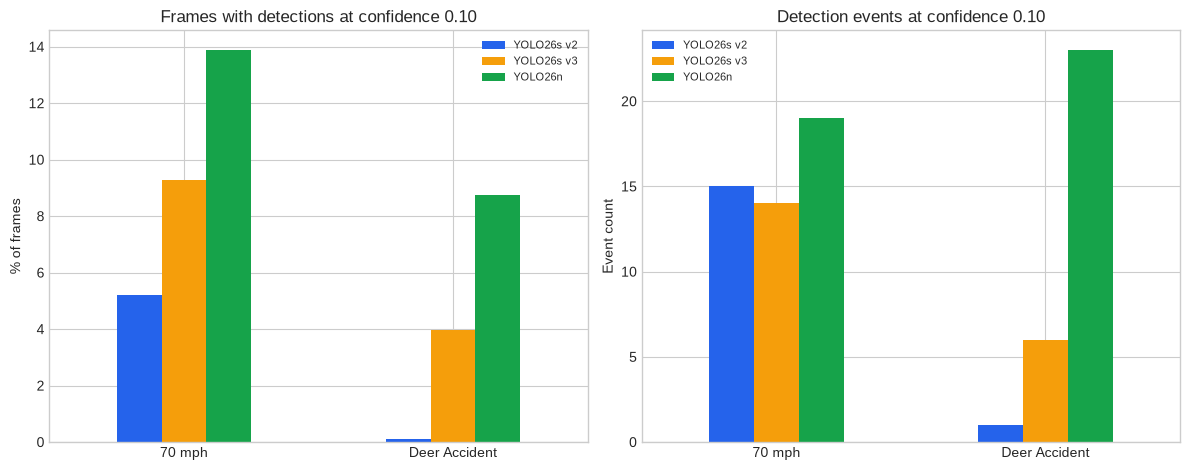

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for axis, metric, title in zip(axes, ['detection_frame_rate_pct', 'events'], ['Frames with detections', 'Detection events']):
    pivot = unseen_df.pivot(index='video', columns='model', values=metric)[list(COLORS)]
    pivot.plot(kind='bar', ax=axis, color=[COLORS[name] for name in pivot.columns], rot=0)
    axis.set_title(title + ' at confidence 0.10')
    axis.set_xlabel('')
    axis.set_ylabel('% of frames' if metric.endswith('pct') else 'Event count')
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. YOLO26n still-image threshold study

,threshold,false_negatives,false_positives,precision,recall,true_positives
0,0.10,4,3,0.7,0.636,7
1,0.25,4,0,1.0,0.636,7


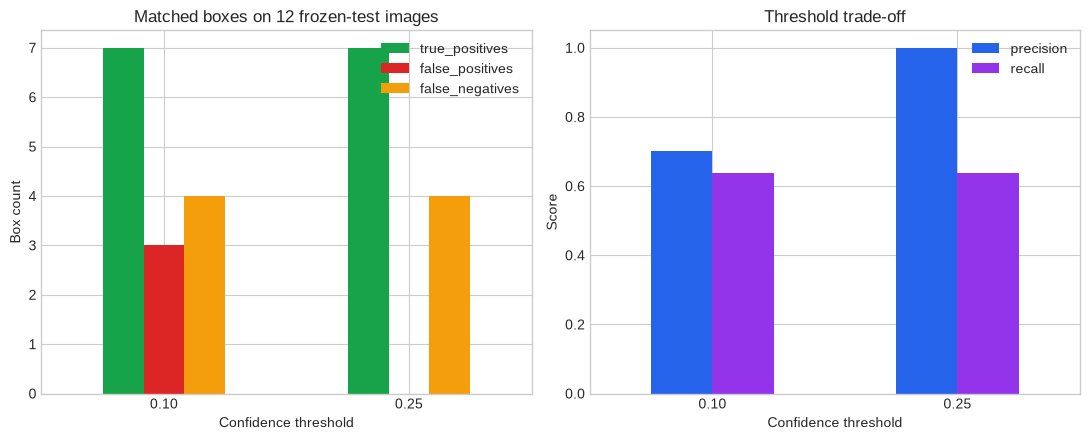

In [9]:
sample_reports = {
    '0.10': load_json('storage/evidence/nano_image_samples_conf010/report.json'),
    '0.25': load_json('storage/evidence/nano_image_samples/report.json'),
}
sample_df = pd.DataFrame([{'threshold': threshold, **report['totals']} for threshold, report in sample_reports.items()])
display(sample_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sample_df.set_index('threshold')[['true_positives', 'false_positives', 'false_negatives']].plot(kind='bar', ax=axes[0], rot=0, color=['#16a34a', '#dc2626', '#f59e0b'])
sample_df.set_index('threshold')[['precision', 'recall']].plot(kind='bar', ax=axes[1], rot=0, color=['#2563eb', '#9333ea'])
axes[0].set_title('Matched boxes on 12 frozen-test images')
axes[0].set_ylabel('Box count')
axes[1].set_title('Threshold trade-off')
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel('Score')
for axis in axes:
    axis.set_xlabel('Confidence threshold')
plt.tight_layout()
plt.show()

Lowering confidence from 0.25 to 0.10 did not recover any of the four missed deer boxes, but it introduced three false positives. This supports 0.25 as the current demo threshold.

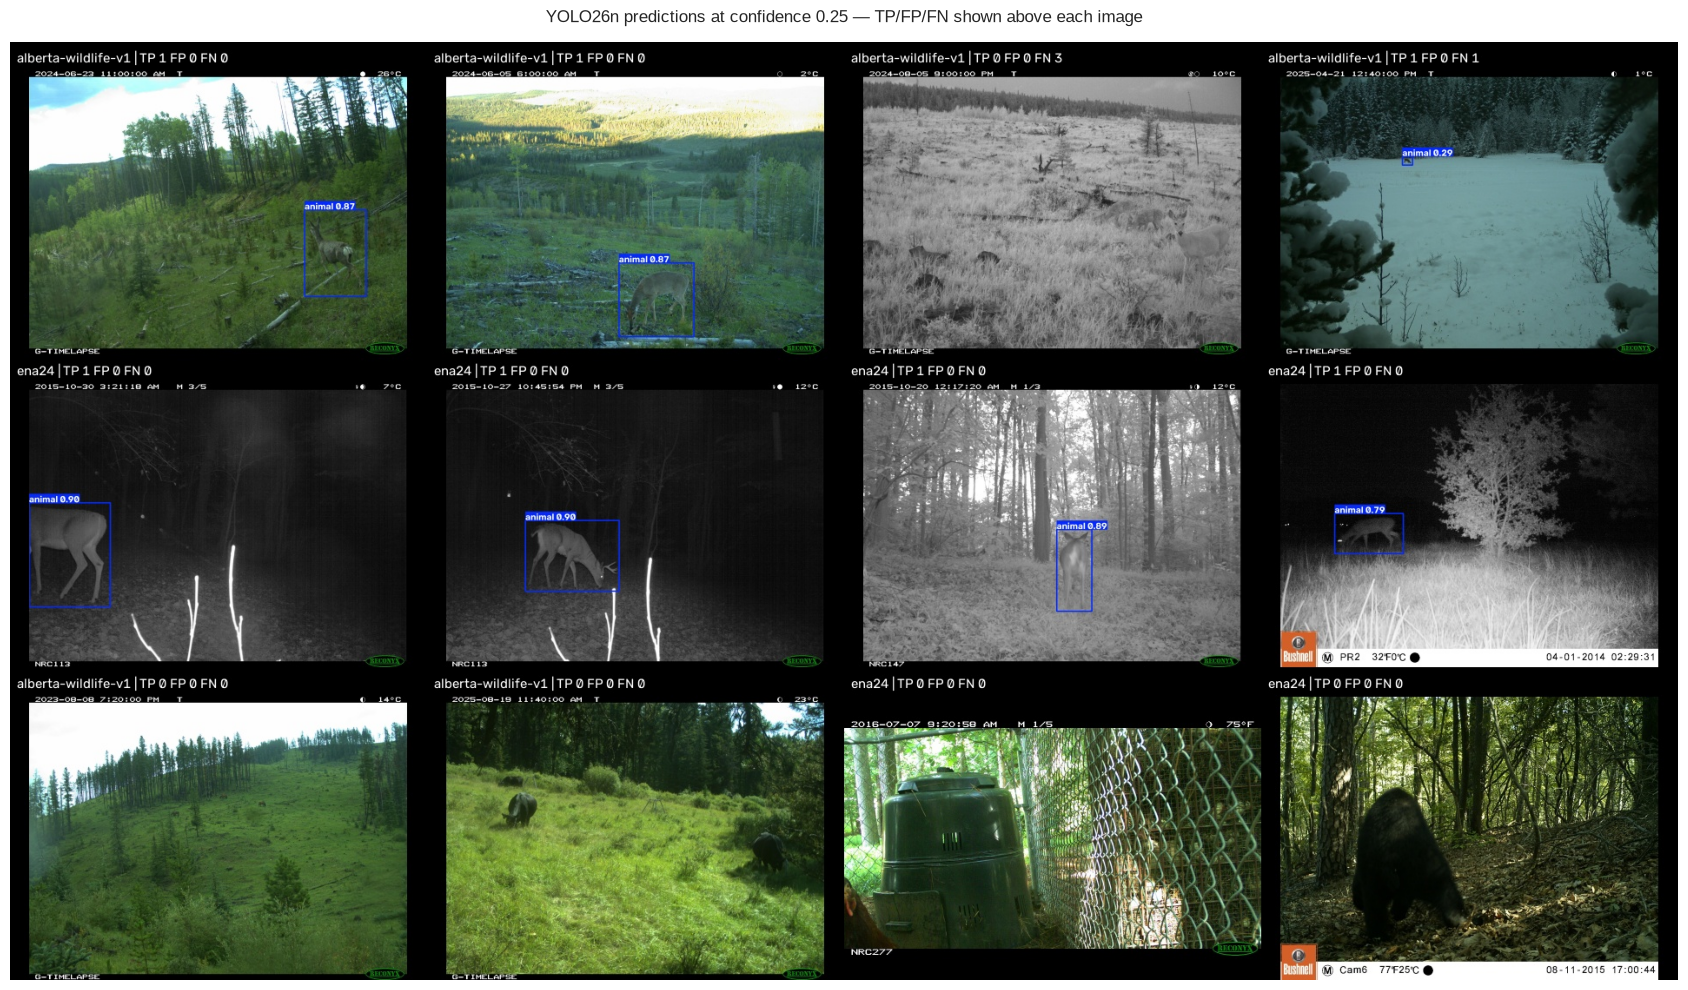

In [10]:
gallery = plt.imread(ROOT / 'storage/evidence/nano_image_samples/gallery.jpg')
fig, ax = plt.subplots(figsize=(18, 10))
ax.imshow(gallery)
ax.axis('off')
ax.set_title('YOLO26n predictions at confidence 0.25 — TP/FP/FN shown above each image', pad=14)
plt.tight_layout()
plt.show()

The gallery shows strong clear-day and infrared detections, no boxes on the sampled horse, cow, chicken, or black bear images, and a clear weakness on small low-contrast deer groups. Although the class is named `animal`, current behavior is primarily deer-specific.

## 6. Personal-video evidence

In [11]:
personal = load_json('storage/evidence/personal_yolo26n_threshold_025/report.json')
personal_df = pd.DataFrame([
    {
        'video': Path(video['source']).stem,
        'duration_s': video['duration_seconds'],
        'detection_frames': video['detection_frames'],
        'detection_frame_rate_pct': 100 * video['detection_frame_rate'],
        'events': len(video['events']),
        'max_confidence': video['max_confidence'],
    }
    for video in personal['videos']
])
display(personal_df.round(3))

,video,duration_s,detection_frames,detection_frame_rate_pct,events,max_confidence
0,A moose-vehicle collision can happen in the bl...,9.133,176,64.234,1,0.591
1,IMG_4073,6.167,140,75.676,1,0.883
2,"Tesla Car Hits Deer $7,000 in damage! (1)",16.133,43,8.884,2,0.867


## Decision

**YOLO26n is the best current hackathon deployment candidate.** It provides the highest frozen-test mAP50–95, the smallest checkpoint, faster comparable inference, and a clean pre-impact Tesla detection at the 0.25 operating threshold.

**YOLO26s v2 remains the conservative fallback.** It has slightly higher precision and recall on the frozen test split and substantially lower alert activity on one unseen clip.

This evidence does not establish a production safety winner. A definitive selection requires an independently annotated road-video benchmark measuring event precision, missed encounters, false alerts per minute, and first-detection time.